Projeto - Python Sudeste 2026


In [ ]:
# ================================
# CÉLULA 1: Setup inicial
# ================================
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score, confusion_matrix, classification_report,
    ConfusionMatrixDisplay, roc_auc_score, roc_curve
)

pd.set_option('display.max_columns', None)
sns.set_style("whitegrid")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# ================================
# CÉLULA 2: Dados de saúde (DATASUS/SINAN)
# ================================
caminho_arquivo = "/content/drive/MyDrive/1 Mestrado/Arboviroses/4 Projeto Arboviroses /Projeto/Dados dengue BH/2023/DENGBR23.csv"
df_bruto = pd.read_csv(caminho_arquivo, low_memory=False)

# --- Diagnóstico do ID_MUNICIP (evita filtro vazio silencioso) ---
print("Tipo da coluna ID_MUNICIP:", df_bruto['ID_MUNICIP'].dtype)
print("Amostra de valores:", df_bruto['ID_MUNICIP'].astype(str).unique()[:5])

# Garante comparação como string para não perder registros por causa de tipo
df_bruto['ID_MUNICIP'] = df_bruto['ID_MUNICIP'].astype(str).str.strip()
df_bh = df_bruto[df_bruto["ID_MUNICIP"] == "310620"].copy()

print(f"\nRegistros encontrados para BH: {len(df_bh)}")
if len(df_bh) == 0:
    raise ValueError("⚠️ Nenhum registro encontrado para BH. Verifique o formato de ID_MUNICIP acima.")

# Tratando as datas
df_bh['DT_NOTIFIC'] = pd.to_datetime(df_bh['DT_NOTIFIC'], format='%Y%m%d', errors='coerce')
print("Datas nulas após conversão:", df_bh['DT_NOTIFIC'].isna().sum())

# Agrupando os casos por dia
casos_por_dia = df_bh.groupby('DT_NOTIFIC').size().reset_index(name='Casos_Dengue')
casos_por_dia = casos_por_dia.rename(columns={'DT_NOTIFIC': 'Data'})

print("\n✅ Dados do DATASUS prontos!")
display(casos_por_dia.head())
print("Período:", casos_por_dia['Data'].min(), "até", casos_por_dia['Data'].max())

Tipo da coluna ID_MUNICIP: int64
Amostra de valores: ['120070' '120005' '120030' '120035' '120039']

Registros encontrados para BH: 21403
Datas nulas após conversão: 0

✅ Dados do DATASUS prontos!


,Data,Casos_Dengue
0,2023-01-01,1
1,2023-01-02,9
2,2023-01-03,5
3,2023-01-04,8
4,2023-01-05,14


Período: 2023-01-01 00:00:00 até 2023-12-30 00:00:00


In [ ]:
# ================================
# CÉLULA 3: Dados climáticos (INMET)
# ================================
nome_arquivo_inmet = '/content/INMET_SE_MG_A521_BELO HORIZONTE (PAMPULHA)_01-01-2023_A_31-12-2023.CSV'

In [ ]:
# --- Detecta a linha do cabeçalho ---
with open(nome_arquivo_inmet, encoding='latin1') as f:
    linhas = f.readlines()

linha_cabecalho = None
for i, linha in enumerate(linhas):
    if not linha.strip():
        continue
    upper = linha.upper()
    if linha.count(';') >= 5 and ('PRECIPITA' in upper or 'TEMPERATURA' in upper):
        linha_cabecalho = i
        break

if linha_cabecalho is None:
    raise ValueError("Cabeçalho não encontrado.")

print(f"Cabeçalho real na linha: {linha_cabecalho}")

# --- Leitura do CSV ---
df_clima = pd.read_csv(
    nome_arquivo_inmet,
    sep=';',
    encoding='latin1',
    skiprows=linha_cabecalho,
    decimal=','
)

df_clima = df_clima.dropna(axis=1, how='all')

print("\nColunas lidas:", df_clima.columns.tolist())

# --- Renomeação ---
mapa_colunas = {}
for col in df_clima.columns:
    col_upper = col.upper()
    if 'DATA' in col_upper and 'HORA' not in col_upper:   # evita 'HORA UTC'
        mapa_colunas[col] = 'Data'
    elif 'PRECIPITA' in col_upper:
        mapa_colunas[col] = 'Chuva'
    elif 'TEMPERATURA MÁXIMA' in col_upper or 'TEMPERATURA MAXIMA' in col_upper:
        mapa_colunas[col] = 'Temp_Max'
    elif 'TEMPERATURA MÍNIMA' in col_upper or 'TEMPERATURA MINIMA' in col_upper:
        mapa_colunas[col] = 'Temp_Min'

df_clima = df_clima.rename(columns=mapa_colunas)

# Verifica se as colunas necessárias existem
colunas_necessarias = ['Data', 'Chuva', 'Temp_Max', 'Temp_Min']
faltando = [c for c in colunas_necessarias if c not in df_clima.columns]
if faltando:
    raise ValueError(f"Colunas não encontradas: {faltando}. Colunas disponíveis: {df_clima.columns.tolist()}")

# Converte Data para datetime
df_clima['Data'] = pd.to_datetime(df_clima['Data'], errors='coerce')

# Converte numéricas
for col in ['Chuva', 'Temp_Max', 'Temp_Min']:
    df_clima[col] = pd.to_numeric(df_clima[col], errors='coerce')

# Agregação diária
clima_por_dia = df_clima.groupby('Data').agg({
    'Chuva': 'sum',
    'Temp_Max': 'max',
    'Temp_Min': 'min'
}).reset_index()

print("\n✅ Dados processados com sucesso!")
display(clima_por_dia.head())
print("Período:", clima_por_dia['Data'].min(), "até", clima_por_dia['Data'].max())

Cabeçalho real na linha: 8

Colunas lidas: ['Data', 'Hora UTC', 'PRECIPITAÇÃO TOTAL, HORÁRIO (mm)', 'PRESSAO ATMOSFERICA AO NIVEL DA ESTACAO, HORARIA (mB)', 'PRESSÃO ATMOSFERICA MAX.NA HORA ANT. (AUT) (mB)', 'PRESSÃO ATMOSFERICA MIN. NA HORA ANT. (AUT) (mB)', 'RADIACAO GLOBAL (Kj/m²)', 'TEMPERATURA DO AR - BULBO SECO, HORARIA (°C)', 'TEMPERATURA DO PONTO DE ORVALHO (°C)', 'TEMPERATURA MÁXIMA NA HORA ANT. (AUT) (°C)', 'TEMPERATURA MÍNIMA NA HORA ANT. (AUT) (°C)', 'TEMPERATURA ORVALHO MAX. NA HORA ANT. (AUT) (°C)', 'TEMPERATURA ORVALHO MIN. NA HORA ANT. (AUT) (°C)', 'UMIDADE REL. MAX. NA HORA ANT. (AUT) (%)', 'UMIDADE REL. MIN. NA HORA ANT. (AUT) (%)', 'UMIDADE RELATIVA DO AR, HORARIA (%)', 'VENTO, DIREÇÃO HORARIA (gr) (° (gr))', 'VENTO, RAJADA MAXIMA (m/s)', 'VENTO, VELOCIDADE HORARIA (m/s)']

✅ Dados processados com sucesso!


,Data,Chuva,Temp_Max,Temp_Min
0,2023-01-01,4.8,26.4,18.9
1,2023-01-02,8.2,26.1,18.3
2,2023-01-03,10.8,26.3,18.6
3,2023-01-04,26.0,26.9,18.1
4,2023-01-05,19.0,23.2,18.6


Período: 2023-01-01 00:00:00 até 2023-12-31 00:00:00


Dados faltantes por coluna:
Data            0
Casos_Dengue    0
Chuva           0
Temp_Max        0
Temp_Min        0
dtype: int64

✅ Dados semanais consolidados!


,Semana,Casos_Dengue,Chuva,Temp_Max,Temp_Min
0,2023-01-01,1.0,4.8,26.400000,18.900000
1,2023-01-08,52.0,211.0,25.600000,18.700000
2,2023-01-15,70.0,62.6,29.371429,18.785714
3,2023-01-22,93.0,143.6,28.700000,18.600000
4,2023-01-29,126.0,62.8,29.485714,19.171429
5,2023-02-05,159.0,19.6,30.942857,19.642857
6,2023-02-12,178.0,35.2,30.200000,18.928571
7,2023-02-19,261.0,64.2,30.785714,19.042857
8,2023-02-26,330.0,0.0,30.385714,19.942857
9,2023-03-05,478.0,0.0,30.942857,19.857143


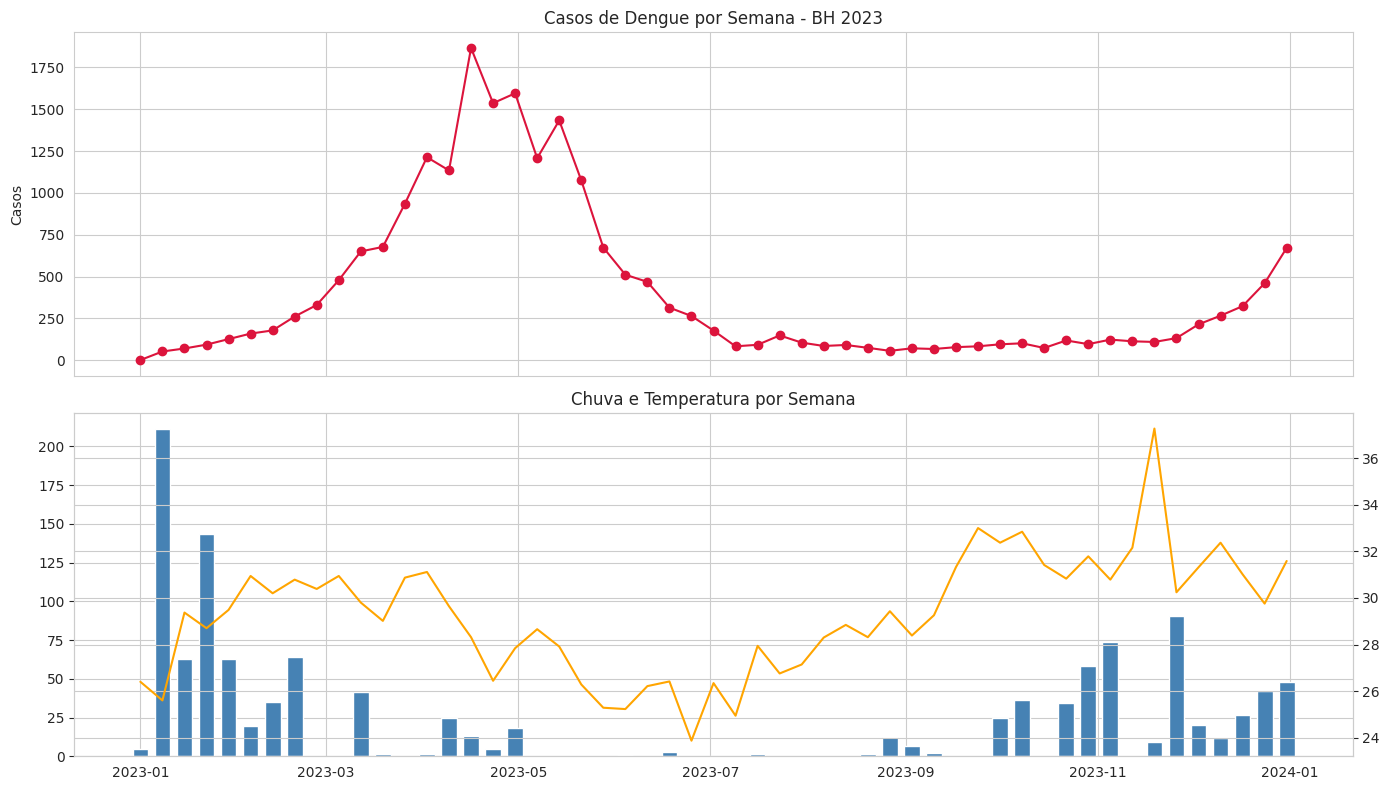

In [ ]:
# ================================
# CÉLULA 4: Merge diário + agregação por semana epidemiológica
# ================================

# Cria um calendário completo do ano (evita "buracos" em dias sem notificação)
calendario = pd.DataFrame({'Data': pd.date_range('2023-01-01', '2023-12-31', freq='D')})

df_diario = calendario.merge(casos_por_dia, on='Data', how='left')
df_diario = df_diario.merge(clima_por_dia, on='Data', how='left')

# Dias sem notificação = 0 casos (não é dado faltante, é ausência de evento)
df_diario['Casos_Dengue'] = df_diario['Casos_Dengue'].fillna(0)

# Para clima, se houver algum dia faltando na estação, interpola
df_diario[['Chuva', 'Temp_Max', 'Temp_Min']] = df_diario[['Chuva', 'Temp_Max', 'Temp_Min']].interpolate()

print("Dados faltantes por coluna:")
print(df_diario.isna().sum())

# --- Agregação semanal ---
df_diario = df_diario.set_index('Data')
df_semanal = df_diario.resample('W').agg({
    'Casos_Dengue': 'sum',
    'Chuva': 'sum',
    'Temp_Max': 'mean',
    'Temp_Min': 'mean'
}).reset_index()

df_semanal = df_semanal.rename(columns={'Data': 'Semana'})

print("\n✅ Dados semanais consolidados!")
display(df_semanal.head(10))

# Visualização rápida
fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
axes[0].plot(df_semanal['Semana'], df_semanal['Casos_Dengue'], color='crimson', marker='o')
axes[0].set_title('Casos de Dengue por Semana - BH 2023')
axes[0].set_ylabel('Casos')

axes[1].bar(df_semanal['Semana'], df_semanal['Chuva'], color='steelblue', width=5, label='Chuva (mm)')
ax2 = axes[1].twinx()
ax2.plot(df_semanal['Semana'], df_semanal['Temp_Max'], color='orange', label='Temp. Máx')
axes[1].set_title('Chuva e Temperatura por Semana')
plt.tight_layout()
plt.show()

In [ ]:
# ================================
# CÉLULA 5: Lags temporais + variável-alvo (Alto/Baixo Risco)
# ================================

df_modelo = df_semanal.copy()

# --- Lags de clima (3 e 4 semanas atrás, simulando o ciclo do mosquito) ---
for lag in [1, 2, 3, 4]:
    df_modelo[f'Chuva_lag{lag}'] = df_modelo['Chuva'].shift(lag)
    df_modelo[f'TempMax_lag{lag}'] = df_modelo['Temp_Max'].shift(lag)
    df_modelo[f'TempMin_lag{lag}'] = df_modelo['Temp_Min'].shift(lag)

# --- Variável-alvo: Alto Risco (1) vs Baixo Risco (0) ---
# Critério: semana com número de casos acima da mediana histórica = Alto Risco
limiar = df_modelo['Casos_Dengue'].median()
df_modelo['Risco'] = (df_modelo['Casos_Dengue'] > limiar).astype(int)

print(f"Limiar de casos usado (mediana): {limiar}")
print("\nDistribuição das classes:")
print(df_modelo['Risco'].value_counts())
print(df_modelo['Risco'].value_counts(normalize=True).round(2))

# Remove linhas iniciais sem lag completo (NaN)
df_modelo = df_modelo.dropna().reset_index(drop=True)

print(f"\nLinhas disponíveis para modelagem após remover NaNs: {len(df_modelo)}")
display(df_modelo.head())

Limiar de casos usado (mediana): 159.0

Distribuição das classes:
Risco
0    27
1    26
Name: count, dtype: int64
Risco
0    0.51
1    0.49
Name: proportion, dtype: float64

Linhas disponíveis para modelagem após remover NaNs: 49


,Semana,Casos_Dengue,Chuva,Temp_Max,Temp_Min,Chuva_lag1,TempMax_lag1,TempMin_lag1,Chuva_lag2,TempMax_lag2,TempMin_lag2,Chuva_lag3,TempMax_lag3,TempMin_lag3,Chuva_lag4,TempMax_lag4,TempMin_lag4,Risco
0,2023-01-29,126.0,62.8,29.485714,19.171429,143.6,28.700000,18.600000,62.6,29.371429,18.785714,211.0,25.600000,18.700000,4.8,26.400000,18.900000,0
1,2023-02-05,159.0,19.6,30.942857,19.642857,62.8,29.485714,19.171429,143.6,28.700000,18.600000,62.6,29.371429,18.785714,211.0,25.600000,18.700000,0
2,2023-02-12,178.0,35.2,30.200000,18.928571,19.6,30.942857,19.642857,62.8,29.485714,19.171429,143.6,28.700000,18.600000,62.6,29.371429,18.785714,1
3,2023-02-19,261.0,64.2,30.785714,19.042857,35.2,30.200000,18.928571,19.6,30.942857,19.642857,62.8,29.485714,19.171429,143.6,28.700000,18.600000,1
4,2023-02-26,330.0,0.0,30.385714,19.942857,64.2,30.785714,19.042857,35.2,30.200000,18.928571,19.6,30.942857,19.642857,62.8,29.485714,19.171429,1


In [ ]:
# ================================
# CÉLULA 6: Preparação para o Machine Learning
# ================================

features = [c for c in df_modelo.columns if 'lag' in c]
X = df_modelo[features]
y = df_modelo['Risco']

print("Features usadas:", features)

# --- Split CRONOLÓGICO (não aleatório) ---
# Em séries temporais, treinar com dados "do futuro" para prever "o passado" é vazamento de dados.
tamanho_treino = int(len(df_modelo) * 0.75)

X_train, X_test = X.iloc[:tamanho_treino], X.iloc[tamanho_treino:]
y_train, y_test = y.iloc[:tamanho_treino], y.iloc[tamanho_treino:]

print(f"\nTreino: {len(X_train)} semanas | Teste: {len(X_test)} semanas")
print("Distribuição treino:", y_train.value_counts().to_dict())
print("Distribuição teste:", y_test.value_counts().to_dict())

# Escalonamento (necessário para Regressão Logística)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

Features usadas: ['Chuva_lag1', 'TempMax_lag1', 'TempMin_lag1', 'Chuva_lag2', 'TempMax_lag2', 'TempMin_lag2', 'Chuva_lag3', 'TempMax_lag3', 'TempMin_lag3', 'Chuva_lag4', 'TempMax_lag4', 'TempMin_lag4']

Treino: 36 semanas | Teste: 13 semanas
Distribuição treino: {1: 21, 0: 15}
Distribuição teste: {0: 8, 1: 5}


REGRESSÃO LOGÍSTICA - RESULTADOS
Acurácia: 61.54%

Relatório de classificação:
              precision    recall  f1-score   support

 Baixo Risco       1.00      0.38      0.55         8
  Alto Risco       0.50      1.00      0.67         5

    accuracy                           0.62        13
   macro avg       0.75      0.69      0.61        13
weighted avg       0.81      0.62      0.59        13



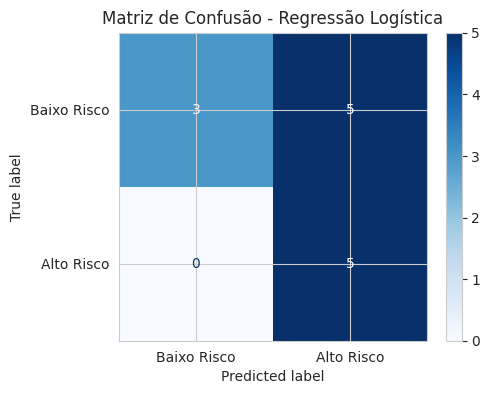


Influência de cada variável (coeficientes):


,Feature,Coeficiente
1,TempMax_lag1,-1.403084
11,TempMin_lag4,1.098023
8,TempMin_lag3,0.788909
5,TempMin_lag2,0.527859
3,Chuva_lag2,-0.516353
0,Chuva_lag1,-0.513379
10,TempMax_lag4,0.480099
4,TempMax_lag2,-0.393044
9,Chuva_lag4,0.289230
6,Chuva_lag3,0.153497


In [ ]:
# ================================
# CÉLULA 7: Regressão Logística (baseline)
# ================================

modelo_lr = LogisticRegression(random_state=42, max_iter=1000)
modelo_lr.fit(X_train_scaled, y_train)

y_pred_lr = modelo_lr.predict(X_test_scaled)
y_proba_lr = modelo_lr.predict_proba(X_test_scaled)[:, 1]

print("=" * 50)
print("REGRESSÃO LOGÍSTICA - RESULTADOS")
print("=" * 50)
print(f"Acurácia: {accuracy_score(y_test, y_pred_lr):.2%}")
print("\nRelatório de classificação:")
print(classification_report(y_test, y_pred_lr, target_names=['Baixo Risco', 'Alto Risco']))

fig, ax = plt.subplots(figsize=(5, 4))
cm = confusion_matrix(y_test, y_pred_lr)
ConfusionMatrixDisplay(cm, display_labels=['Baixo Risco', 'Alto Risco']).plot(ax=ax, cmap='Blues')
plt.title('Matriz de Confusão - Regressão Logística')
plt.show()

# Coeficientes (interpretação do modelo)
coef_df = pd.DataFrame({
    'Feature': features,
    'Coeficiente': modelo_lr.coef_[0]
}).sort_values('Coeficiente', key=abs, ascending=False)

print("\nInfluência de cada variável (coeficientes):")
display(coef_df)

RANDOM FOREST - RESULTADOS
Acurácia: 38.46%

Relatório de classificação:
              precision    recall  f1-score   support

 Baixo Risco       0.00      0.00      0.00         8
  Alto Risco       0.38      1.00      0.56         5

    accuracy                           0.38        13
   macro avg       0.19      0.50      0.28        13
weighted avg       0.15      0.38      0.21        13



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


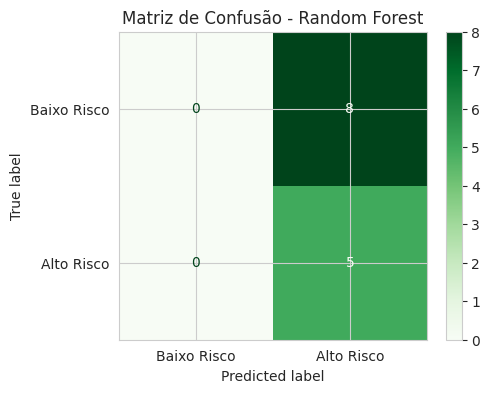

/tmp/ipykernel_11802/3858757362.py:36: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=importancia_df, x='Importância', y='Feature', palette='viridis')


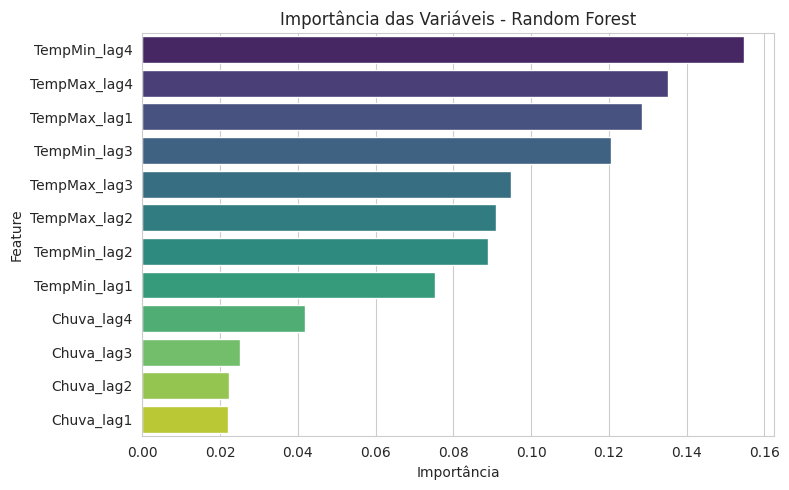

In [ ]:
# ================================
# CÉLULA 8: Random Forest
# ================================

modelo_rf = RandomForestClassifier(
    n_estimators=200,
    max_depth=5,          # limitado por causa do dataset pequeno (evita overfitting)
    min_samples_leaf=2,
    random_state=42
)
modelo_rf.fit(X_train, y_train)  # Random Forest não precisa de scaling

y_pred_rf = modelo_rf.predict(X_test)
y_proba_rf = modelo_rf.predict_proba(X_test)[:, 1]

print("=" * 50)
print("RANDOM FOREST - RESULTADOS")
print("=" * 50)
print(f"Acurácia: {accuracy_score(y_test, y_pred_rf):.2%}")
print("\nRelatório de classificação:")
print(classification_report(y_test, y_pred_rf, target_names=['Baixo Risco', 'Alto Risco']))

fig, ax = plt.subplots(figsize=(5, 4))
cm_rf = confusion_matrix(y_test, y_pred_rf)
ConfusionMatrixDisplay(cm_rf, display_labels=['Baixo Risco', 'Alto Risco']).plot(ax=ax, cmap='Greens')
plt.title('Matriz de Confusão - Random Forest')
plt.show()

# Importância das features (ótimo slide para a palestra!)
importancia_df = pd.DataFrame({
    'Feature': features,
    'Importância': modelo_rf.feature_importances_
}).sort_values('Importância', ascending=False)

plt.figure(figsize=(8, 5))
sns.barplot(data=importancia_df, x='Importância', y='Feature', palette='viridis')
plt.title('Importância das Variáveis - Random Forest')
plt.tight_layout()
plt.show()

,Modelo,Acurácia,AUC-ROC
0,Regressão Logística,0.615385,0.750
1,Random Forest,0.384615,0.725


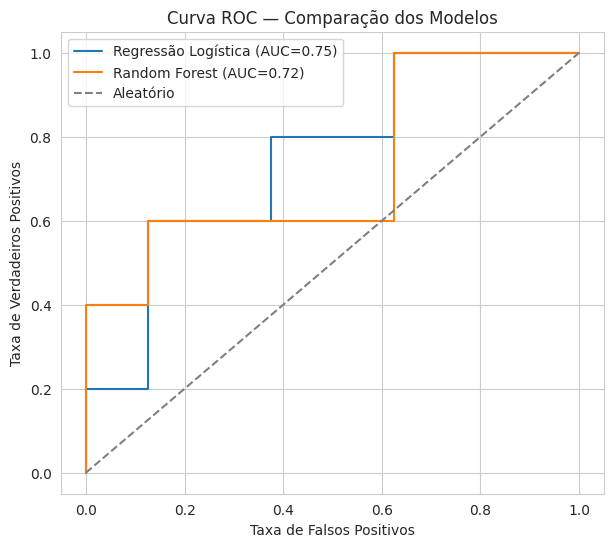

In [ ]:
# ================================
# CÉLULA 9: Comparação Logistic Regression vs Random Forest
# ================================

comparacao = pd.DataFrame({
    'Modelo': ['Regressão Logística', 'Random Forest'],
    'Acurácia': [accuracy_score(y_test, y_pred_lr), accuracy_score(y_test, y_pred_rf)],
    'AUC-ROC': [roc_auc_score(y_test, y_proba_lr), roc_auc_score(y_test, y_proba_rf)]
})
display(comparacao)

# Curvas ROC lado a lado
plt.figure(figsize=(7, 6))
for nome, proba in [('Regressão Logística', y_proba_lr), ('Random Forest', y_proba_rf)]:
    fpr, tpr, _ = roc_curve(y_test, proba)
    auc = roc_auc_score(y_test, proba)
    plt.plot(fpr, tpr, label=f'{nome} (AUC={auc:.2f})')

plt.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Aleatório')
plt.xlabel('Taxa de Falsos Positivos')
plt.ylabel('Taxa de Verdadeiros Positivos')
plt.title('Curva ROC — Comparação dos Modelos')
plt.legend()
plt.show()

In [ ]:
# ================================
# CÉLULA 10: Melhorias - TimeSeriesSplit, class_weight e ajuste de limiar
# ================================
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import precision_recall_curve, f1_score

# ---------------------------------------------------------
# PARTE A: Validação cruzada temporal (mais robusta que 1 split único)
# ---------------------------------------------------------
tscv = TimeSeriesSplit(n_splits=5)

resultados_lr = []
resultados_rf = []
folds_validos = []

print("=" * 60)
print("VALIDAÇÃO CRUZADA TEMPORAL (5 splits)")
print("=" * 60)

for i, (idx_train, idx_test) in enumerate(tscv.split(X)):
    X_tr, X_te = X.iloc[idx_train], X.iloc[idx_test]
    y_tr, y_te = y.iloc[idx_train], y.iloc[idx_test]

    if y_te.nunique() < 2:
        continue
    folds_validos.append(i + 1)

    scaler_cv = StandardScaler()
    X_tr_scaled = scaler_cv.fit_transform(X_tr)
    X_te_scaled = scaler_cv.transform(X_te)

    # Logistic Regression com class_weight balanceado
    lr_cv = LogisticRegression(random_state=42, max_iter=1000, class_weight='balanced')
    lr_cv.fit(X_tr_scaled, y_tr)
    auc_lr = roc_auc_score(y_te, lr_cv.predict_proba(X_te_scaled)[:, 1])
    resultados_lr.append(auc_lr)

    # Random Forest com class_weight balanceado
    rf_cv = RandomForestClassifier(
        n_estimators=200, max_depth=5, min_samples_leaf=2,
        class_weight='balanced', random_state=42
    )
    rf_cv.fit(X_tr, y_tr)
    auc_rf = roc_auc_score(y_te, rf_cv.predict_proba(X_te)[:, 1])
    resultados_rf.append(auc_rf)

    print(f"Fold {i+1}: treino={len(idx_train)} semanas, teste={len(idx_test)} semanas | "
          f"AUC LR={auc_lr:.2f} | AUC RF={auc_rf:.2f}")

print(f"\nAUC médio LR: {np.mean(resultados_lr):.2f} (+/- {np.std(resultados_lr):.2f})")
print(f"AUC médio RF: {np.mean(resultados_rf):.2f} (+/- {np.std(resultados_rf):.2f})")

VALIDAÇÃO CRUZADA TEMPORAL (5 splits)
Fold 2: treino=17 semanas, teste=8 semanas | AUC LR=0.58 | AUC RF=0.75
Fold 5: treino=41 semanas, teste=8 semanas | AUC LR=0.73 | AUC RF=0.20

AUC médio LR: 0.66 (+/- 0.08)
AUC médio RF: 0.47 (+/- 0.28)



MODELOS FINAIS COM class_weight='balanced'


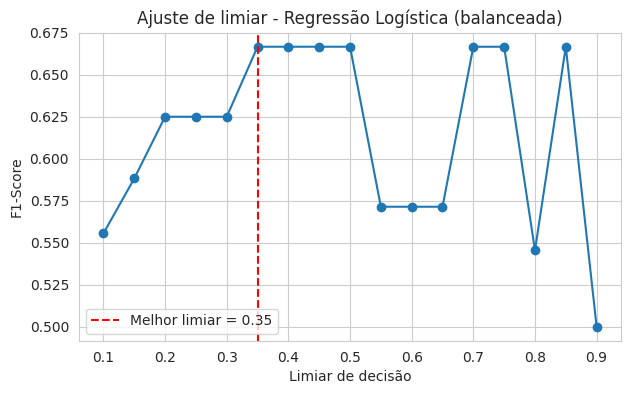

Regressão Logística (balanceada): melhor limiar = 0.35 (F1 = 0.67)


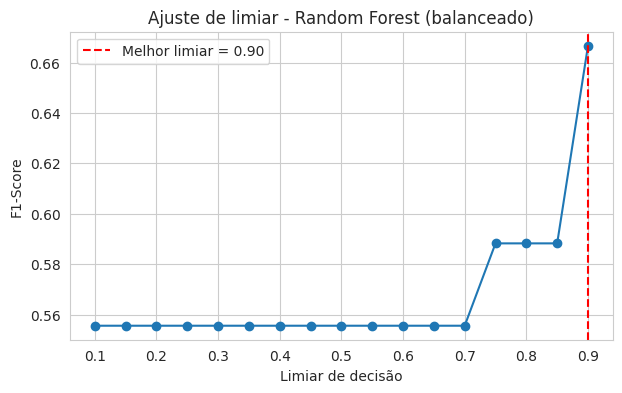

Random Forest (balanceado): melhor limiar = 0.90 (F1 = 0.67)


In [ ]:
# ---------------------------------------------------------
# PARTE B: Retreinar no split original, agora com class_weight='balanced'
# ---------------------------------------------------------
print("\n" + "=" * 60)
print("MODELOS FINAIS COM class_weight='balanced'")
print("=" * 60)

modelo_lr_bal = LogisticRegression(random_state=42, max_iter=1000, class_weight='balanced')
modelo_lr_bal.fit(X_train_scaled, y_train)
y_proba_lr_bal = modelo_lr_bal.predict_proba(X_test_scaled)[:, 1]

modelo_rf_bal = RandomForestClassifier(
    n_estimators=200, max_depth=5, min_samples_leaf=2,
    class_weight='balanced', random_state=42
)
modelo_rf_bal.fit(X_train, y_train)
y_proba_rf_bal = modelo_rf_bal.predict_proba(X_test)[:, 1]

# ---------------------------------------------------------
# PARTE C: Ajuste do limiar de decisão (em vez do 0.5 padrão)
# ---------------------------------------------------------
def melhor_limiar(y_true, y_proba, nome_modelo):
    """Testa limiares de 0.1 a 0.9 e escolhe o que maximiza F1."""
    limiares = np.arange(0.1, 0.95, 0.05)
    melhores_f1 = []
    for lim in limiares:
        pred = (y_proba >= lim).astype(int)
        melhores_f1.append(f1_score(y_true, pred, zero_division=0))

    idx_melhor = np.argmax(melhores_f1)
    lim_otimo = limiares[idx_melhor]

    plt.figure(figsize=(7, 4))
    plt.plot(limiares, melhores_f1, marker='o')
    plt.axvline(lim_otimo, color='red', linestyle='--', label=f'Melhor limiar = {lim_otimo:.2f}')
    plt.xlabel('Limiar de decisão')
    plt.ylabel('F1-Score')
    plt.title(f'Ajuste de limiar - {nome_modelo}')
    plt.legend()
    plt.show()

    print(f"{nome_modelo}: melhor limiar = {lim_otimo:.2f} (F1 = {melhores_f1[idx_melhor]:.2f})")
    return lim_otimo

lim_lr = melhor_limiar(y_test, y_proba_lr_bal, "Regressão Logística (balanceada)")
lim_rf = melhor_limiar(y_test, y_proba_rf_bal, "Random Forest (balanceado)")

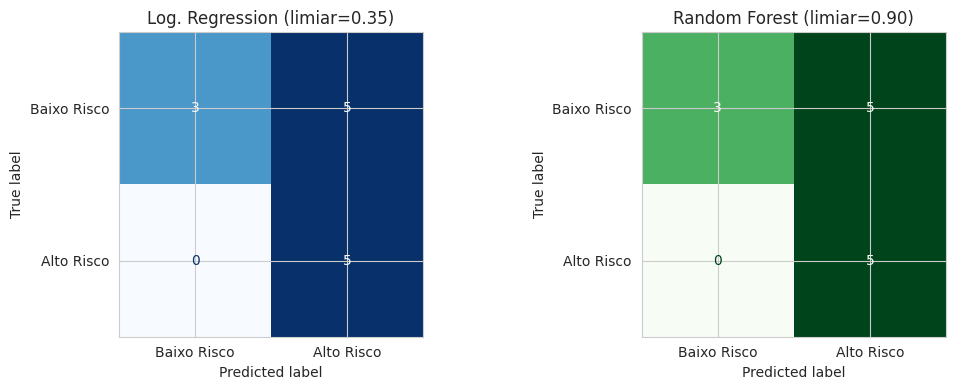

REGRESSÃO LOGÍSTICA (balanceada + limiar ajustado)
              precision    recall  f1-score   support

 Baixo Risco       1.00      0.38      0.55         8
  Alto Risco       0.50      1.00      0.67         5

    accuracy                           0.62        13
   macro avg       0.75      0.69      0.61        13
weighted avg       0.81      0.62      0.59        13


RANDOM FOREST (balanceado + limiar ajustado)
              precision    recall  f1-score   support

 Baixo Risco       1.00      0.38      0.55         8
  Alto Risco       0.50      1.00      0.67         5

    accuracy                           0.62        13
   macro avg       0.75      0.69      0.61        13
weighted avg       0.81      0.62      0.59        13



,Modelo,Acurácia,F1-Score (Alto Risco)
0,LR (original),0.615385,0.666667
1,LR (balanceado+limiar),0.615385,0.666667
2,RF (original),0.384615,0.555556
3,RF (balanceado+limiar),0.615385,0.666667


In [ ]:
# ---------------------------------------------------------
# PARTE D: Resultado final com limiar otimizado
# ---------------------------------------------------------
y_pred_lr_final = (y_proba_lr_bal >= lim_lr).astype(int)
y_pred_rf_final = (y_proba_rf_bal >= lim_rf).astype(int)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

cm_lr_final = confusion_matrix(y_test, y_pred_lr_final)
ConfusionMatrixDisplay(cm_lr_final, display_labels=['Baixo Risco', 'Alto Risco']).plot(
    ax=axes[0], cmap='Blues', colorbar=False
)
axes[0].set_title(f'Log. Regression (limiar={lim_lr:.2f})')

cm_rf_final = confusion_matrix(y_test, y_pred_rf_final)
ConfusionMatrixDisplay(cm_rf_final, display_labels=['Baixo Risco', 'Alto Risco']).plot(
    ax=axes[1], cmap='Greens', colorbar=False
)
axes[1].set_title(f'Random Forest (limiar={lim_rf:.2f})')

plt.tight_layout()
plt.show()

print("REGRESSÃO LOGÍSTICA (balanceada + limiar ajustado)")
print(classification_report(y_test, y_pred_lr_final, target_names=['Baixo Risco', 'Alto Risco']))

print("\nRANDOM FOREST (balanceado + limiar ajustado)")
print(classification_report(y_test, y_pred_rf_final, target_names=['Baixo Risco', 'Alto Risco']))

# Comparativo final: antes vs depois
comparativo_final = pd.DataFrame({
    'Modelo': ['LR (original)', 'LR (balanceado+limiar)', 'RF (original)', 'RF (balanceado+limiar)'],
    'Acurácia': [
        accuracy_score(y_test, y_pred_lr),
        accuracy_score(y_test, y_pred_lr_final),
        accuracy_score(y_test, y_pred_rf),
        accuracy_score(y_test, y_pred_rf_final),
    ],
    'F1-Score (Alto Risco)': [
        f1_score(y_test, y_pred_lr, pos_label=1),
        f1_score(y_test, y_pred_lr_final, pos_label=1),
        f1_score(y_test, y_pred_rf, pos_label=1),
        f1_score(y_test, y_pred_rf_final, pos_label=1),
    ]
})
display(comparativo_final)

/tmp/ipykernel_11802/484626032.py:13: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  box = axes[0].boxplot(


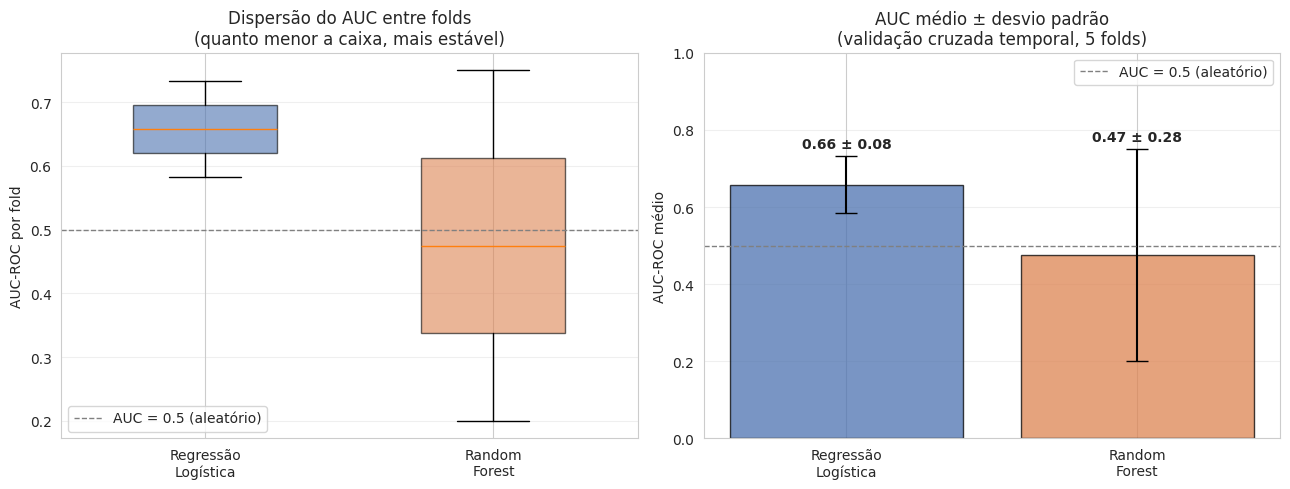

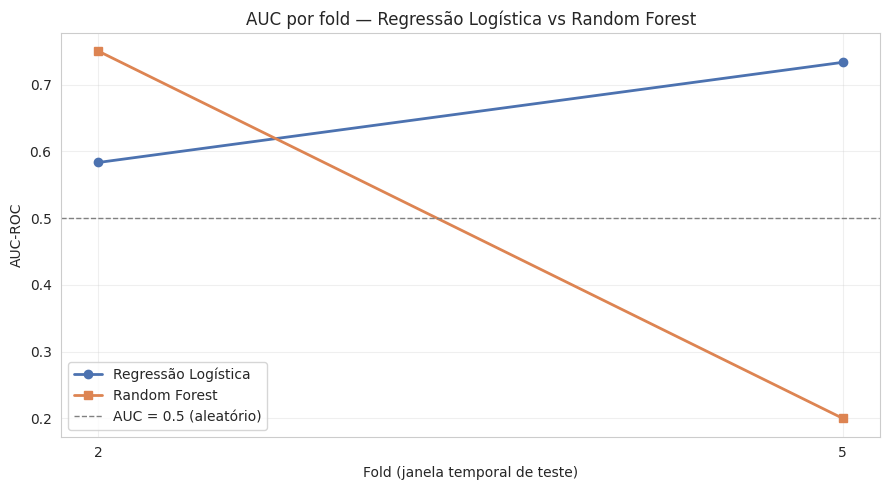

Regressão Logística — Desvio padrão do AUC: 0.075
Random Forest — Desvio padrão do AUC: 0.275

Random Forest é 3.7x mais instável que a Regressão Logística


In [ ]:
# ================================
# CÉLULA 11: Comparação visual de estabilidade (LR vs RF) entre folds
# ================================

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# ---------------------------------------------------------
# GRÁFICO A: Boxplot comparando a dispersão do AUC
# ---------------------------------------------------------
dados_boxplot = [resultados_lr, resultados_rf]
labels_boxplot = ['Regressão\nLogística', 'Random\nForest']

box = axes[0].boxplot(
    dados_boxplot,
    labels=labels_boxplot,
    patch_artist=True,
    widths=0.5
)

cores = ['#4C72B0', '#DD8452']
for patch, cor in zip(box['boxes'], cores):
    patch.set_facecolor(cor)
    patch.set_alpha(0.6)

axes[0].axhline(0.5, color='gray', linestyle='--', linewidth=1, label='AUC = 0.5 (aleatório)')
axes[0].set_ylabel('AUC-ROC por fold')
axes[0].set_title('Dispersão do AUC entre folds\n(quanto menor a caixa, mais estável)')
axes[0].legend()
axes[0].grid(axis='y', alpha=0.3)

# ---------------------------------------------------------
# GRÁFICO B: Barras com média +/- desvio padrão
# ---------------------------------------------------------
medias = [np.mean(resultados_lr), np.mean(resultados_rf)]
desvios = [np.std(resultados_lr), np.std(resultados_rf)]

bars = axes[1].bar(
    labels_boxplot,
    medias,
    yerr=desvios,
    capsize=8,
    color=cores,
    alpha=0.75,
    edgecolor='black'
)

axes[1].axhline(0.5, color='gray', linestyle='--', linewidth=1, label='AUC = 0.5 (aleatório)')

# Anota o valor médio em cima de cada barra
for bar, media, desvio in zip(bars, medias, desvios):
    axes[1].text(
        bar.get_x() + bar.get_width() / 2,
        media + desvio + 0.02,
        f'{media:.2f} ± {desvio:.2f}',
        ha='center',
        fontsize=10,
        fontweight='bold'
    )

axes[1].set_ylabel('AUC-ROC médio')
axes[1].set_title('AUC médio ± desvio padrão\n(validação cruzada temporal, 5 folds)')
axes[1].set_ylim(0, 1)
axes[1].legend()
axes[1].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# GRÁFICO C (bônus): evolução do AUC fold a fold — mostra a instabilidade do RF "ao vivo"
# ---------------------------------------------------------
plt.figure(figsize=(9, 5))
folds_x = folds_validos   # usa os números reais dos folds (2 e 5, não 1 e 2)

plt.plot(folds_x, resultados_lr, marker='o', color='#4C72B0', linewidth=2, label='Regressão Logística')
plt.plot(folds_x, resultados_rf, marker='s', color='#DD8452', linewidth=2, label='Random Forest')
plt.axhline(0.5, color='gray', linestyle='--', linewidth=1, label='AUC = 0.5 (aleatório)')

plt.xlabel('Fold (janela temporal de teste)')
plt.ylabel('AUC-ROC')
plt.title('AUC por fold — Regressão Logística vs Random Forest')
plt.xticks(list(folds_x))
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Regressão Logística — Desvio padrão do AUC: {np.std(resultados_lr):.3f}")
print(f"Random Forest — Desvio padrão do AUC: {np.std(resultados_rf):.3f}")
print(f"\nRandom Forest é {np.std(resultados_rf)/np.std(resultados_lr):.1f}x mais instável que a Regressão Logística")